In [4]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()

rotas = [
    ("GIG", "GRU", 340),
    ("GIG", "BSB", 930),
    ("GRU", "CNF", 490),
    ("GRU", "REC", 2100),
    ("BSB", "CNF", 620),
    ("CNF", "REC", 1650),
]

for origem, destino, distancia in rotas:
    G.add_edge(origem, destino, weight=distancia)

print("Número de aeroportos:", G.number_of_nodes())
print("Número de rotas:", G.number_of_edges())

Número de aeroportos: 5
Número de rotas: 6


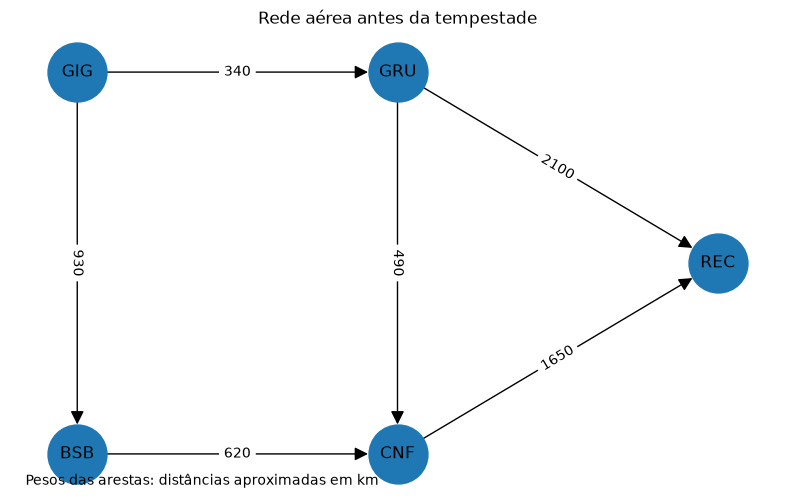

In [5]:
pos = {
    "GIG": (0, 1),
    "GRU": (1, 1),
    "BSB": (0, 0),
    "CNF": (1, 0),
    "REC": (2, 0.5),
}

plt.figure(figsize=(10, 6))

nx.draw_networkx(
    G,
    pos,
    with_labels=True,
    node_size=1800,
    arrows=True,
    arrowsize=20
)

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=nx.get_edge_attributes(G, "weight")
)

plt.title("Rede aérea antes da tempestade")
plt.text(
    0.02, 0.02,
    "Pesos das arestas: distâncias aproximadas em km",
    transform=plt.gca().transAxes
)
plt.axis("off")
plt.show()

In [6]:
G_tempestade = G.copy()
G_tempestade.remove_edge("GRU", "REC")

print("Rotas antes:", G.number_of_edges())
print("Rotas depois:", G_tempestade.number_of_edges())

Rotas antes: 6
Rotas depois: 5


In [7]:
G_tempestade = G.copy()
G_tempestade.remove_edge("GRU", "REC")

print("Rotas antes:", G.number_of_edges())
print("Rotas depois:", G_tempestade.number_of_edges())

Rotas antes: 6
Rotas depois: 5


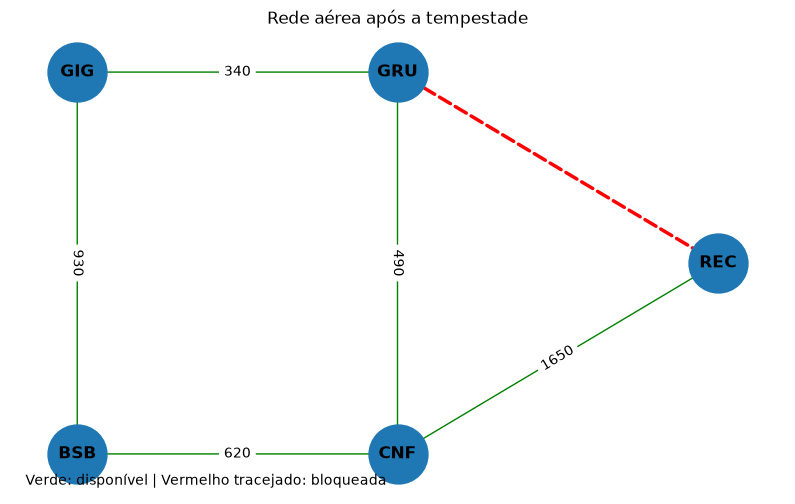

In [8]:
plt.figure(figsize=(10, 6))

# Desenha os aeroportos
nx.draw_networkx_nodes(
    G_tempestade, pos, node_size=1800
)
nx.draw_networkx_labels(
    G_tempestade, pos, font_weight="bold"
)

# Desenha as rotas que continuam disponíveis
nx.draw_networkx_edges(
    G_tempestade, pos,
    edge_color="green",
    arrows=True,
    arrowsize=20
)

nx.draw_networkx_edge_labels(
    G_tempestade, pos,
    edge_labels=nx.get_edge_attributes(
        G_tempestade, "weight"
    )
)

# Sobrepõe a rota bloqueada em vermelho tracejado
nx.draw_networkx_edges(
    G, pos,
    edgelist=[("GRU", "REC")],
    edge_color="red",
    style="dashed",
    width=2.5,
    arrows=True,
    arrowsize=20
)

plt.title("Rede aérea após a tempestade")
plt.text(
    0.02, 0.02,
    "Verde: disponível | Vermelho tracejado: bloqueada",
    transform=plt.gca().transAxes
)
plt.axis("off")
plt.show()

In [9]:
origem = "GIG"
destino = "REC"

for nome, grafo in [
    ("Antes da tempestade", G),
    ("Depois da tempestade", G_tempestade)
]:
    try:
        caminho = nx.dijkstra_path(
            grafo, origem, destino, weight="weight"
        )
        distancia = nx.dijkstra_path_length(
            grafo, origem, destino, weight="weight"
        )

        print(f"\n{nome}")
        print("Caminho:", " -> ".join(caminho))
        print("Distância:", distancia, "km")

    except nx.NetworkXNoPath:
        print(f"\n{nome}: não há caminho disponível.")


Antes da tempestade
Caminho: GIG -> GRU -> REC
Distância: 2440 km

Depois da tempestade
Caminho: GIG -> GRU -> CNF -> REC
Distância: 2480 km


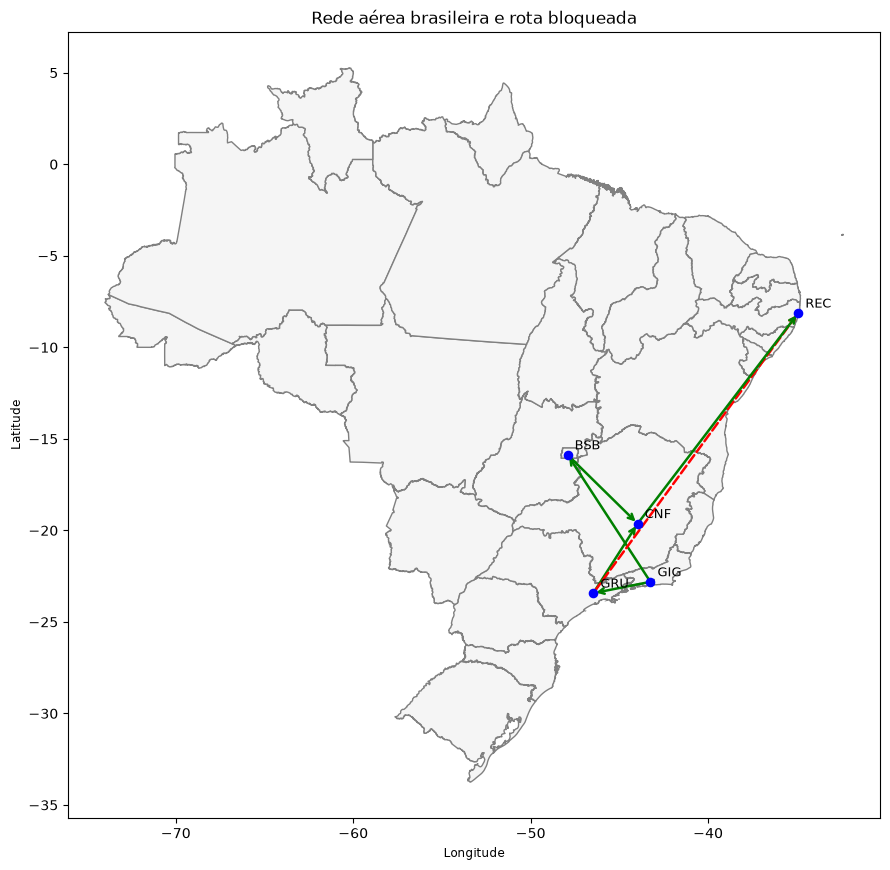

In [11]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Mapa dos estados brasileiros
url = (
    "https://raw.githubusercontent.com/"
    "codeforamerica/click_that_hood/master/"
    "public/data/brazil-states.geojson"
)

brasil = gpd.read_file(url)

# Coordenadas aproximadas dos aeroportos
aeroportos = {
    "GIG": (-43.25, -22.81),
    "GRU": (-46.47, -23.43),
    "BSB": (-47.92, -15.87),
    "CNF": (-43.97, -19.63),
    "REC": (-34.92, -8.13)
}

# Rotas: origem, destino, distância em km
rotas = [
    ("GIG", "GRU", 340),
    ("GIG", "BSB", 930),
    ("GRU", "CNF", 490),
    ("GRU", "REC", 2100),
    ("BSB", "CNF", 620),
    ("CNF", "REC", 1650)
]

fig, ax = plt.subplots(figsize=(9, 9))

# Desenha o mapa de fundo
brasil.plot(ax=ax, color="whitesmoke", edgecolor="gray")

# Desenha as rotas e os aeroportos
for origem, destino, distancia in rotas:
    x1, y1 = aeroportos[origem]
    x2, y2 = aeroportos[destino]

    bloqueada = (origem, destino) == ("GRU", "REC")

    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops={
            "arrowstyle": "->",
            "color": "red" if bloqueada else "green",
            "linestyle": "--" if bloqueada else "-",
            "linewidth": 1.8
        }
    )

# Marca e identifica os aeroportos
for codigo, (lon, lat) in aeroportos.items():
    ax.scatter(lon, lat, color="blue", s=35, zorder=3)
    ax.text(lon + 0.4, lat + 0.3, codigo, fontsize=9)

ax.set_title("Rede aérea brasileira e rota bloqueada")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.savefig("mapa_brasil.png", dpi=200)
plt.show()